In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Classroom', 'CO1_Fundamentals of Computers_Lecture1.gdoc', 'FSWD_Activity Set#1_HTML.docx', 'CO2_Intro_to_C_Lecture2&3.gdoc', 'DS_CA_Session1 (3).1_RVU.gdoc', 'DS_CA_Session1 (2).1_RVU.gdoc', 'DS_CA_Session1 (1).1_RVU.gdoc', 'DS_CA_Session1.1_RVU.gdoc', 'C03As2P4.c', 'Co-4 and Co-5.pptx', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'Charging and Discharging of a capacitor in a RC circuit.gdoc', 'Untitled document (1).gdoc', 'Practise (1).c', 'Practise.c', 'Project presentation  template.pptx', 'Circuitrix-Light Up RVU-Fisrt slide format.gslides', 'Co-1 and Co-2.gslides', 'Co-3 (1).gslides', 'Section-B.gdoc', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (5).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (4).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (3).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (2).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (1).pptx', '_Circu

In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/IEMOCAP dataset"

print("Top level folders:")
print(os.listdir(dataset_path))

Top level folders:
['IEMOCAP_full_release_withoutVideos.tar.gz', 'IEMOCAP_X_all.npy', 'IEMOCAP_y_all.npy']


In [ ]:
!tar -xvzf "/content/drive/MyDrive/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos.tar.gz" -C /content/

Streaming output truncated to the last 5000 lines.
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M030.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M021.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F007.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F003.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M033.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F013.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F022.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M012.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M016.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses0

In [ ]:
dataset_path = "/content/IEMOCAP_full_release"

**Multimodal - Random Forest ( Audio - MFCC features, Text - BERT)**

In [ ]:
# ==============================================
# 🔥 LOAD IEMOCAP DATA (AUDIO + TEXT + LABELS)
# ==============================================

import os
import glob

DATA_PATH = "/content/IEMOCAP_full_release"

valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths = []
transcripts = []
labels = []

for session in range(1, 6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")

    # Get all wav files
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        # Emotion annotation file
        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(session_path, "dialog", "EmoEvaluation", ann_name)

        # Transcript file
        trans_path = os.path.join(session_path, "dialog", "transcriptions", ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        # -----------------------------
        # GET EMOTION LABEL
        # -----------------------------
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue

        if emotion == "exc":
            emotion = "hap"

        # -----------------------------
        # GET TRANSCRIPT
        # -----------------------------
        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        # -----------------------------
        # STORE
        # -----------------------------
        wav_paths.append(wav_file)
        transcripts.append(text)
        labels.append(emotion)

print("✅ Total samples:", len(wav_paths))

✅ Total samples: 5621


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
100%|██████████| 5621/5621 [03:28<00:00, 26.92it/s]


Class Weights: {np.int64(0): np.float64(1.2643419572553432), np.int64(1): np.float64(0.8495842781557067), np.int64(2): np.float64(0.8005698005698005), np.int64(3): np.float64(1.2772727272727273)}

Accuracy: 0.48977777777777776

Classification Report:

              precision    recall  f1-score   support

           0       0.62      0.27      0.38       223
           1       0.42      0.48      0.45       331
           2       0.46      0.60      0.52       351
           3       0.62      0.55      0.59       220

    accuracy                           0.49      1125
   macro avg       0.53      0.48      0.48      1125
weighted avg       0.51      0.49      0.48      1125


✅ Multimodal Emotion Trend Analysis Completed!

Sample Conversations: ['Ses01F_impro01', 'Ses01F_impro02', 'Ses01F_impro03', 'Ses01F_impro04', 'Ses01F_impro05', 'Ses01F_impro06', 'Ses01F_impro07', 'Ses01F_script01', 'Ses01F_script02', 'Ses01F_script03']

Enter Conversation ID: Ses01F_impro05


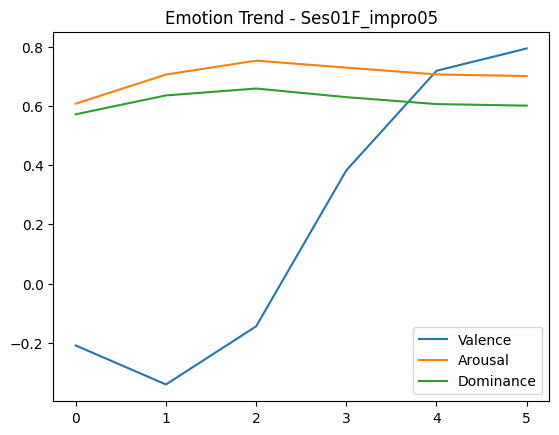

📌 Positive emotional progression


In [ ]:
# ==============================================
# 🔥 MULTIMODAL EMOTION RECOGNITION (FINAL)
# ==============================================

!pip install librosa transformers scikit-learn -q

import os
import re
import json
import librosa
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import BertTokenizer, BertModel

# -------------------------------------------------
# 🔧 DEVICE
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# 🎧 AUDIO FEATURE (MFCC)
# -------------------------------------------------
def extract_mfcc(file_path, max_len=100):
    signal, sr = librosa.load(file_path, sr=16000)
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)

    if mfcc.shape[1] < max_len:
        mfcc = np.pad(mfcc, ((0,0),(0, max_len - mfcc.shape[1])))
    else:
        mfcc = mfcc[:, :max_len]

    return mfcc.flatten()

# -------------------------------------------------
# 📝 TEXT FEATURE (BERT)
# -------------------------------------------------
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased").to(device)
bert_model.eval()

def extract_text_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:, 0, :].cpu().numpy().flatten()

# -------------------------------------------------
# 📂 YOUR DATA (REPLACE THESE)
# -------------------------------------------------
# wav_paths = [...]
# transcripts = [...]
# labels = [...]

data = []
for i in range(len(wav_paths)):
    data.append({
        "audio_path": wav_paths[i],
        "text": transcripts[i],
        "label": labels[i]
    })

# -------------------------------------------------
# 🔗 FEATURE EXTRACTION + FUSION
# -------------------------------------------------
X, y, paths = [], [], []

for item in tqdm(data):
    audio_feat = extract_mfcc(item["audio_path"])
    text_feat = extract_text_embedding(item["text"])

    fused = np.concatenate([audio_feat, text_feat])

    X.append(fused)
    y.append(item["label"])
    paths.append(item["audio_path"])

X = np.array(X)
y = np.array(y)

# -------------------------------------------------
# 🔢 LABEL ENCODING
# -------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(y)

# -------------------------------------------------
# ✂️ TRAIN-TEST SPLIT
# -------------------------------------------------
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, paths, test_size=0.2, random_state=42, stratify=y
)

# -------------------------------------------------
# ⚖️ CLASS IMBALANCE HANDLING
# -------------------------------------------------
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(zip(np.unique(y_train), class_weights))
print("Class Weights:", class_weight_dict)

# -------------------------------------------------
# 📉 PCA
# -------------------------------------------------
pca = PCA(n_components=100)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# -------------------------------------------------
# 🌳 MODEL (Random Forest + Weights)
# -------------------------------------------------
model = RandomForestClassifier(
    n_estimators=200,
    class_weight=class_weight_dict
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

# -------------------------------------------------
# 📊 EVALUATION
# -------------------------------------------------
print("\nAccuracy:", accuracy_score(y_test, preds))
print("\nClassification Report:\n")
print(classification_report(y_test, preds))

pred_labels = le.inverse_transform(preds)

# -------------------------------------------------
# 🔗 CREATE CONVERSATION DATAFRAME
# -------------------------------------------------
records = []

for idx, (path, pred) in enumerate(zip(paths_test, pred_labels)):
    filename = os.path.basename(path).replace(".wav", "")
    parts = filename.split("_")

    conversation_id = "_".join(parts[:2]) if len(parts) >= 2 else filename

    match = re.search(r'[MF](\d+)', filename)
    utterance_id = int(match.group(1)) if match else idx

    records.append({
        "conversation_id": conversation_id,
        "utterance_id": utterance_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records)
df = df.sort_values(by=["conversation_id", "utterance_id"])

# -------------------------------------------------
# 📊 EMOTION TREND ANALYSIS (VAD)
# -------------------------------------------------
VAD_MAP = {
    "hap": (0.8, 0.7, 0.6),
    "sad": (-0.7, 0.3, 0.4),
    "ang": (-0.6, 0.8, 0.7),
    "neu": (0.0, 0.5, 0.5)
}

os.makedirs("plots", exist_ok=True)

results = []
vad_sequences = {}

for conv_id, group in df.groupby("conversation_id"):

    group = group.sort_values("utterance_id")
    emotions = group["emotion_label"].tolist()

    vad = np.array([VAD_MAP[e] for e in emotions])

    val, aro, dom = vad[:,0], vad[:,1], vad[:,2]

    val_s = gaussian_filter1d(val, sigma=1)
    aro_s = gaussian_filter1d(aro, sigma=1)
    dom_s = gaussian_filter1d(dom, sigma=1)

    trend = val_s[-1] - val_s[0]
    transitions = sum(1 for i in range(1,len(emotions)) if emotions[i]!=emotions[i-1])

    results.append({
        "conversation_id": conv_id,
        "mean_valence": np.mean(val),
        "trend": trend,
        "transitions": transitions
    })

    vad_sequences[conv_id] = {
        "valence": val.tolist(),
        "arousal": aro.tolist(),
        "dominance": dom.tolist()
    }

    # Plot
    plt.figure()
    x = range(len(val))

    plt.plot(x, val_s, label="Valence")
    plt.plot(x, aro_s, linestyle="--", label="Arousal")
    plt.plot(x, dom_s, linestyle=":", label="Dominance")

    plt.title(f"Emotion Trend - {conv_id}")
    plt.xlabel("Utterance Index")
    plt.ylabel("Emotion Intensity")
    plt.legend()

    plt.savefig(f"plots/{conv_id}.png")
    plt.close()

# Save outputs
pd.DataFrame(results).to_csv("emotion_stats.csv", index=False)

with open("vad_sequences.json", "w") as f:
    json.dump(vad_sequences, f, indent=4)

print("\n✅ Multimodal Emotion Trend Analysis Completed!")

# -------------------------------------------------
# 🎯 USER VISUALIZATION
# -------------------------------------------------
with open("vad_sequences.json", "r") as f:
    vad_data = json.load(f)

print("\nSample Conversations:", list(vad_data.keys())[:10])

conv_id = input("\nEnter Conversation ID: ")

if conv_id in vad_data:
    val = np.array(vad_data[conv_id]["valence"])
    aro = np.array(vad_data[conv_id]["arousal"])
    dom = np.array(vad_data[conv_id]["dominance"])

    val_s = gaussian_filter1d(val, 1)

    plt.plot(val_s, label="Valence")
    plt.plot(gaussian_filter1d(aro,1), label="Arousal")
    plt.plot(gaussian_filter1d(dom,1), label="Dominance")

    plt.legend()
    plt.title(f"Emotion Trend - {conv_id}")
    plt.show()

    trend = val_s[-1] - val_s[0]

    if trend > 0.2:
        print("📌 Positive emotional progression")
    elif trend < -0.2:
        print("📌 Negative emotional decline")
    else:
        print("📌 Emotion is stable")

else:
    print("❌ Invalid Conversation ID")

**Multimodal - MLP Model( Audio - MFCC features, Text - BERT)**

✅ Total samples: 5621


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
100%|██████████| 5621/5621 [03:04<00:00, 30.46it/s]


Epoch 1, Loss: 1.0314
Epoch 2, Loss: 0.8384
Epoch 3, Loss: 0.7596
Epoch 4, Loss: 0.7029
Epoch 5, Loss: 0.6643
Epoch 6, Loss: 0.6148
Epoch 7, Loss: 0.5612
Epoch 8, Loss: 0.5435
Epoch 9, Loss: 0.5055
Epoch 10, Loss: 0.4782
Epoch 11, Loss: 0.4506
Epoch 12, Loss: 0.4303
Epoch 13, Loss: 0.4084
Epoch 14, Loss: 0.3811
Epoch 15, Loss: 0.3809
Epoch 16, Loss: 0.3506
Epoch 17, Loss: 0.3465
Epoch 18, Loss: 0.3135
Epoch 19, Loss: 0.3049
Epoch 20, Loss: 0.3007
Epoch 21, Loss: 0.2745
Epoch 22, Loss: 0.2823
Epoch 23, Loss: 0.2749
Epoch 24, Loss: 0.2755
Epoch 25, Loss: 0.2412
Epoch 26, Loss: 0.2325
Epoch 27, Loss: 0.2276
Epoch 28, Loss: 0.2278
Epoch 29, Loss: 0.2351
Epoch 30, Loss: 0.2378

Accuracy: 0.6702222222222223
              precision    recall  f1-score   support

           0       0.70      0.78      0.74       223
           1       0.68      0.64      0.66       331
           2       0.65      0.60      0.62       351
           3       0.66      0.72      0.69       220

    accuracy     

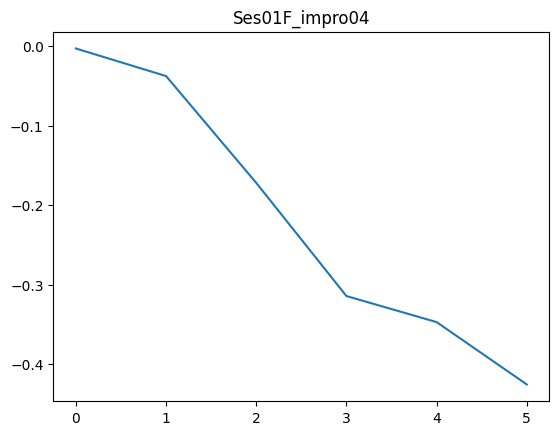

📌 Negative


In [ ]:
# ==============================================
# 🔥 FINAL MULTIMODAL EMOTION RECOGNITION (FIXED)
# ==============================================

!pip install librosa transformers scikit-learn -q

import os, re, glob, json
import librosa
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import BertTokenizer, BertModel

# -------------------------------------------------
# DEVICE
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# LOAD DATA
# -------------------------------------------------
DATA_PATH = "/content/IEMOCAP_full_release"
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths, transcripts, labels = [], [], []

for session in range(1, 6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        ann_name = "_".join(parts[:2]) + ".txt" if "impro" in file_id else "_".join(parts[:3]) + ".txt"
        ann_path = os.path.join(session_path, "dialog", "EmoEvaluation", ann_name)
        trans_path = os.path.join(session_path, "dialog", "transcriptions", ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        # Emotion
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue
        if emotion == "exc":
            emotion = "hap"

        # Text
        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        wav_paths.append(wav_file)
        transcripts.append(text)
        labels.append(emotion)

print("✅ Total samples:", len(wav_paths))

# -------------------------------------------------
# AUDIO FEATURE (MFCC)
# -------------------------------------------------
def extract_mfcc(file_path, max_len=100):
    signal, sr = librosa.load(file_path, sr=16000)
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)

    if mfcc.shape[1] < max_len:
        mfcc = np.pad(mfcc, ((0,0),(0,max_len-mfcc.shape[1])))
    else:
        mfcc = mfcc[:, :max_len]

    return mfcc.flatten()

# -------------------------------------------------
# TEXT FEATURE (BERT)
# -------------------------------------------------
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased").to(device)
bert_model.eval()

def extract_text_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:,0,:].cpu().numpy().flatten()

# -------------------------------------------------
# FEATURE EXTRACTION
# -------------------------------------------------
X, y, paths = [], [], []

for i in tqdm(range(len(wav_paths))):
    audio_feat = extract_mfcc(wav_paths[i])
    text_feat = extract_text_embedding(transcripts[i])

    X.append(np.concatenate([audio_feat, text_feat]))
    y.append(labels[i])
    paths.append(wav_paths[i])

X = np.array(X)
y = np.array(y)

# -------------------------------------------------
# ENCODING
# -------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(y)

# -------------------------------------------------
# SPLIT
# -------------------------------------------------
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, paths, test_size=0.2, stratify=y, random_state=42
)

# -------------------------------------------------
# NORMALIZATION (VERY IMPORTANT)
# -------------------------------------------------
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------------------------------
# PCA
# -------------------------------------------------
pca = PCA(n_components=100)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# -------------------------------------------------
# CLASS WEIGHTS
# -------------------------------------------------
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw = torch.tensor(cw, dtype=torch.float32).to(device)

# -------------------------------------------------
# MODEL
# -------------------------------------------------
class EmotionMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = EmotionMLP(X_train.shape[1], len(np.unique(y))).to(device)

# -------------------------------------------------
# TRAINING SETUP
# -------------------------------------------------
train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test)
    ),
    batch_size=32
)

criterion = nn.CrossEntropyLoss(weight=cw)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

# -------------------------------------------------
# TRAINING
# -------------------------------------------------
for epoch in range(30):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        preds = model(xb)
        loss = criterion(preds, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

# -------------------------------------------------
# EVALUATION
# -------------------------------------------------
model.eval()
all_preds = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        preds = torch.argmax(model(xb), dim=1)
        all_preds.extend(preds.cpu().numpy())

print("\nAccuracy:", accuracy_score(y_test, all_preds))
print(classification_report(y_test, all_preds))

pred_labels = le.inverse_transform(all_preds)

# -------------------------------------------------
# CONVERSATION GROUPING
# -------------------------------------------------
records = []

for idx, (path, pred) in enumerate(zip(paths_test, pred_labels)):
    filename = os.path.basename(path).replace(".wav", "")
    parts = filename.split("_")

    conv_id = "_".join(parts[:2])
    match = re.search(r'[MF](\d+)', filename)
    utt_id = int(match.group(1)) if match else idx

    records.append({
        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records).sort_values(by=["conversation_id","utterance_id"])

# -------------------------------------------------
# EMOTION TREND (VAD)
# -------------------------------------------------
VAD_MAP = {
    "hap": (0.8,0.7,0.6),
    "sad": (-0.7,0.3,0.4),
    "ang": (-0.6,0.8,0.7),
    "neu": (0.0,0.5,0.5)
}

os.makedirs("plots", exist_ok=True)

for cid, grp in df.groupby("conversation_id"):
    emotions = grp["emotion_label"].tolist()
    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:,0],1)
    aro = gaussian_filter1d(vad[:,1],1)
    dom = gaussian_filter1d(vad[:,2],1)

    plt.plot(val, label="Valence")
    plt.plot(aro, label="Arousal")
    plt.plot(dom, label="Dominance")

    plt.legend()
    plt.title(cid)
    plt.savefig(f"plots/{cid}.png")
    plt.close()

# -------------------------------------------------
# USER QUERY
# -------------------------------------------------
print(df["conversation_id"].unique()[:10])
cid = input("Enter conversation ID: ")

subset = df[df["conversation_id"] == cid]

if len(subset) > 0:
    emotions = subset["emotion_label"].tolist()
    vad = np.array([VAD_MAP[e] for e in emotions])
    val = gaussian_filter1d(vad[:,0],1)

    plt.plot(val)
    plt.title(cid)
    plt.show()

    trend = val[-1] - val[0]
    print("📌 Positive" if trend>0 else "📌 Negative" if trend<0 else "📌 Stable")